# LAB019: curvas completas de fermentación y primera prueba EKF (0–166 h)

Comparamos tres trayectorias con las mismas condiciones iniciales y parámetros:
**simulación libre**, **EKF con CO₂** y **EKF con CO₂ + azúcar total/YAN a 22 y 40 h**.
Las curvas se calculan hasta la última muestra química, a 166 h, con el pulso de nitrógeno
registrado a 64,333 h. No se incorporan otras muestras químicas al filtro.
El pulso procede del calendario nutricional del dataset; el indicador automático del logger
permanece en cero y no se utiliza para reconstruir ese aporte.

El estado físico contiene únicamente **biomasa viable, nitrógeno, glucosa, fructosa, etanol,
CO₂ disuelto y O₂**. Biomasa muerta y glicerol no son estados, no tienen covarianzas y no
se grafican ni se evalúan. La memoria auxiliar necesaria para el modelo postnutrición se
explica en el anexo técnico.

**Cómo leer los resultados:** cada figura presenta una variable a lo largo de toda la
fermentación; los tres paneles corresponden a los tres escenarios y comparten escalas.
Las líneas son las trayectorias predichas, los círculos negros son muestras reservadas y
las estrellas rojas son exclusivamente las dos muestras de azúcar/YAN asimiladas.
La línea vertical gris identifica la nutrición. Se omiten bandas y diagramas de diagnóstico
de las figuras principales para facilitar la comparación de las curvas.

El ensayo es exploratorio. No se reajustan parámetros ni matrices contra las muestras
reservadas. Las matrices, comprobaciones y límites están después de las curvas.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, platform, time
from datetime import datetime
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import scipy
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'fermentation_model/shared').is_dir())
FM = ROOT/'fermentation_model'
sys.path.insert(0, str(FM))
from shared import run_new_must_glycerol_estimability_doe as base
get_ipython().run_line_magic('matplotlib', 'inline')

assert Path(sys.prefix).name.lower() == 'fermentation', sys.executable
path_parts = [p.rstrip('\\').lower() for p in os.environ['PATH'].split(';') if p]
lib = r'D:\anaconda3\envs\fermentation\Library\bin'.lower()
idaes = r'C:\Users\claud\AppData\Local\idaes\bin'.lower()
assert path_parts.index(lib) < path_parts.index(idaes) and path_parts.count(idaes) == 1
assert path_parts[-1] == idaes
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': .2,
                     'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
HORIZON = 166.
CHEM_TIMES = (22., 40.)
BIN_H = .5
LOD = .05
FACTOR = 44.0095*60*.74/(1000*24.16*2)
PHYSICAL = ['X','N','G','F','E','Cd','O2']
STATE = PHYSICAL + ['X_ref','N_ref','G_ref','F_ref','E_ref']
NS = len(STATE)
NA = NS+1
IX = {s:i for i,s in enumerate(STATE)}
UNITS = ['g/L']*6+['mg/L']+['g/L']*5
CHANNELS = {'GF':'GF_g_l','N':'N_kg_m3','E':'E_g_l','X':'X_viable_g_l'}
V2 = FM/'laboratory_2026/results/co2_lab016_021_recalibration_v2'
V3 = FM/'laboratory_2026/notebooks/diagnostics/co2_lab016_021_recalibration_v3_artifacts'
INOC = FM/'laboratory_2026/results/nitrogen_consumption_diagnosis/inoculum_viable_weighted/initial_conditions.csv'
RAW = FM/'data/mem2026/LAB019-021'
INPUTS = [RAW/'backup_global_co2_completo.csv', RAW/'backup_global_temperatura_completo.csv',
          V2/'chemistry_observations_corrected_YAN.csv', V2/'initial_conditions.csv',
          V2/'manifest.json', V3/'fit_parameters.csv', INOC,
          FM/'laboratory_2026/results/estimability_historical_natural/theta_natural_full.csv',
          Path(base.__file__)]
def sha(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda:f.read(2**20), b''): h.update(b)
    return h.hexdigest()
HASHES = {str(p.relative_to(ROOT)):sha(p) for p in INPUTS}
T0 = pd.Timestamp('2026-09-21 17:00:00', tz='America/Santiago').tz_convert('UTC')
print(sys.executable, '\nInicio UTC:', T0, '\nFuente biológica:', base.__file__)

D:\anaconda3\envs\fermentation\python.exe 
Inicio UTC: 2026-09-21 20:00:00+00:00 
Fuente biológica: D:\claud\Desktop\Universidad\Memoria\Model\pyomo-doe\fermentation_model\shared\run_new_must_glycerol_estimability_doe.py


## Datos disponibles y qué se entrega al filtro

Se leen los registros crudos completos ya presentes en la caché LFS local, sin descargar ni
modificar datos. CO₂ se resume en ventanas completadas de 30 minutos; el tratamiento de picos
usa sólo los dos minutos previos. La temperatura se retiene desde el último minuto completado.
No se usa filtrado centrado ni información futura.

La química inicial se toma de la muestra previa a inoculación, conservando su mapeo histórico
a t=0 (desfase de 70 min). Biomasa viable inicial: inóculo común, sin ponderación con biomasa
posterior del lote. Las muestras completas de 22 y 40 h se excluyen del contraste reservado
para los tres escenarios, aunque sólo se asimilan azúcar total y YAN en el tercero.

In [2]:
def local_content(path):
    head=path.read_bytes()[:200] if path.stat().st_size<1024 else b''
    if not head.startswith(b'version https://git-lfs.github.com/spec/v1'):return path
    oid=next(line.split('sha256:')[1] for line in head.decode().splitlines() if line.startswith('oid '))
    content=ROOT/'.git/lfs/objects'/oid[:2]/oid[2:4]/oid
    assert content.is_file() and sha(content)==oid, f'Objeto LFS local no disponible: {oid}'
    if content not in INPUTS:
        INPUTS.append(content);HASHES[str(content.relative_to(ROOT))]=oid
    return content

def read_raw(path, columns):
    path=local_content(path)
    pieces=[]
    lo = (T0-pd.Timedelta(hours=1)).tz_convert('America/Santiago').tz_localize(None)
    hi = (T0+pd.Timedelta(hours=HORIZON)).tz_convert('America/Santiago').tz_localize(None)
    for chunk in pd.read_csv(path, usecols=columns, chunksize=300000):
        stamp = pd.to_datetime(chunk.timestamp, errors='raise')
        keep = chunk.fermentador.eq('F1') & stamp.between(lo,hi)
        if keep.any():
            part=chunk.loc[keep].copy()
            part['timestamp']=pd.DatetimeIndex(stamp[keep]).tz_localize(
                'America/Santiago', ambiguous='raise', nonexistent='raise').tz_convert('UTC')
            pieces.append(part)
    out=pd.concat(pieces).sort_values('timestamp').reset_index(drop=True)
    assert out.timestamp.is_unique
    out['t_h']=(out.timestamp-T0).dt.total_seconds()/3600
    return out

raw_gas=read_raw(RAW/'backup_global_co2_completo.csv',['timestamp','fermentador','flow_sccm','status'])
raw_temp=read_raw(RAW/'backup_global_temperatura_completo.csv',['timestamp','fermentador','T','nutricion_activa'])
assert raw_gas.t_h.max() > HORIZON-1/60 and raw_temp.t_h.max() > HORIZON-1/60
print('Estados de nutrición en logger:',raw_temp.nutricion_activa.astype(str).value_counts().to_dict())

# Robust causal despiking: the reference window ends at the sample being processed.
flow=raw_gas.set_index('timestamp').flow_sccm.astype(float)
roll=flow.rolling('120s', min_periods=5)
median=roll.median()
mad=roll.apply(lambda a:np.median(np.abs(a-np.median(a))),raw=True)
spike=(flow-median).abs() > np.maximum(3.5*1.4826*mad,.5)
clean=flow.where(~spike,median)
raw_gas['despiked_sccm']=clean.to_numpy()
raw_gas['spike']=spike.to_numpy()
rows=[]
for end in np.arange(BIN_H,HORIZON+1e-8,BIN_H):
    d=raw_gas[raw_gas.t_h.gt(end-BIN_H)&raw_gas.t_h.le(end)]
    gaps=np.diff(np.r_[end-BIN_H,d.t_h.to_numpy(),end])
    valid=len(d)>=30 and gaps.max()<=2/60
    rows.append(dict(t_h=end, q=d.despiked_sccm.mean()*FACTOR,
                     q_raw=d.flow_sccm.mean()*FACTOR,n=len(d),valid=valid,
                     max_gap_min=60*gaps.max(),spikes=int(d.spike.sum())))
gas_obs=pd.DataFrame(rows)
eligible=gas_obs.valid & gas_obs.q.ge(LOD)
gas_obs['assimilate']=eligible & eligible.shift(fill_value=False)
print('Ventanas sin soporte suficiente (no asimiladas):',int((~gas_obs.valid).sum()))

# Causal temperature: median of each completed minute, held until next completion.
raw_temp['minute']=np.floor(raw_temp.t_h*60).astype(int)
temp=raw_temp.groupby('minute').agg(T=('T','median'),last=('t_h','max')).reset_index()
temp['available_h']=(temp.minute+1)/60
def temperature(t):
    j=np.searchsorted(temp.available_h.to_numpy(),t+1e-12,side='right')-1
    assert j>=0
    assert temp.available_h.iloc[j]<=t+1e-10
    return float(temp['T'].iloc[j])

chem=pd.read_csv(V2/'chemistry_observations_corrected_YAN.csv')
chem=chem[chem.lab.eq('LAB019') & chem.t_h.between(0,HORIZON)].copy()
chem=chem[~chem.is_NUT.astype(str).str.lower().eq('true')].sort_values('t_h')
chem['role']=np.where(chem.t_h.eq(0),'inicial',
                     np.where(chem.t_h.isin(CHEM_TIMES),'asimilable GF+N / muestra excluida','reservada'))
display(chem[['sample','t_h','role','GF_g_l','N_kg_m3','E_g_l','GF_zero_substitution']])
display(gas_obs.agg({'n':['min','max'],'q':['min','max'],'max_gap_min':['max'],'spikes':['sum']}))
print('Bins de CO₂:',len(gas_obs),'asimilados:',gas_obs.assimilate.sum(),
      'primera disponibilidad:',gas_obs.loc[gas_obs.assimilate,'t_h'].min())

Estados de nutrición en logger: {'0': 172748}


Ventanas sin soporte suficiente (no asimiladas): 0


,sample,t_h,role,GF_g_l,N_kg_m3,E_g_l,GF_zero_substitution
0,1,0.0,inicial,158.16,0.230025,12.075372,False
1,2,16.0,reservada,144.94,0.201972,NaN,False
2,3,19.0,reservada,145.55,0.187211,NaN,False
3,4,22.0,asimilable GF+N / muestra excluida,151.22,0.183211,13.732776,False
4,5,40.0,asimilable GF+N / muestra excluida,136.87,0.130114,NaN,False
5,6,43.0,reservada,129.50,0.099831,NaN,False
6,7,46.0,reservada,127.72,0.078194,18.231444,False
7,8,64.0,reservada,89.86,0.000000,NaN,False
9,9,67.5,reservada,81.43,0.035513,NaN,False
10,10,70.5,reservada,72.34,0.019168,33.069156,False


,n,q,max_gap_min,spikes
min,108.0,0.001717,NaN,NaN
max,176.0,0.731374,0.366667,NaN
sum,NaN,NaN,NaN,5035.0


Bins de CO₂: 332 asimilados: 208 primera disponibilidad: 23.0


In [3]:
theta_table=pd.read_csv(INPUTS[7])
theta=dict(zip(theta_table.parameter,theta_table.theta))
manifest=json.loads((V2/'manifest.json').read_text(encoding='utf-8'))
gas_params=manifest['old_gas_start'].copy()
fits=pd.read_csv(V3/'fit_parameters.csv')
choice=fits[(fits.theta=='theta_full')&(fits.training=='train_016_018')&
            (fits.stage=='Z1')&(fits['mode']=='v2')&(fits.filtering=='offline_30min')&
            (fits.temperature=='reference_20_45')]
assert len(choice)==1
for key in ['kCO2_release_h','CO2sat_scale','matrix_gain']:gas_params[key]=float(choice.iloc[0][key])
ini=chem.loc[chem.t_h.eq(0)].iloc[0]
inoc=pd.read_csv(INOC).set_index('lab').loc['LAB019']
initial_table=pd.read_csv(V2/'initial_conditions.csv').set_index('lab')
import ast
N_EVENTS=ast.literal_eval(initial_table.loc['LAB019','N_events'])
assert len(N_EVENTS)==1 and abs(N_EVENTS[0][0]-64.3333333333333)<1e-8
TP,DOSE=map(float,N_EVENTS[0])
oxygen0=gas_params['O2_initial_scale']*max(8.6*np.exp(-.024*(temperature(0)-20)
                      -.002*max(ini.E_g_l,0)-.001*max(ini.G_g_l+ini.F_g_l,0)),1e-6)
physical0=np.array([inoc.common_X0_g_l,ini.N_kg_m3,ini.G_g_l,ini.F_g_l,ini.E_g_l,0.,oxygen0])
x0=np.r_[physical0,physical0[:5]]
S0=x0[2]+x0[3]
SCALE=np.r_[[.3,.25,80.,80.,15.,.2,2.],[.3,.25,80.,80.,15.]]
sd0=np.array([x0[0],.015,1.,np.sqrt(5),.5,.05,.5*x0[6]])
Pphysical=np.diag(sd0**2);Pphysical[2,3]=Pphysical[3,2]=-1.
# Reference memory starts from exactly the same uncertain initial biological state.
B=np.vstack([np.eye(7),np.eye(7)[:5]])
P0=B@Pphysical@B.T
P0z=P0/np.outer(SCALE,SCALE)
Rgas=.04**2;Rchem=np.diag([2.**2,.015**2])
display(pd.DataFrame({'variable':PHYSICAL,'inicial':physical0,'sigma_inicial':sd0,
                      'unidad':['g/L']*6+['mg/L']}))
print(f'Nutrición: +{DOSE:.3f} g/L de N a {TP:.3f} h. Química asimilada: {CHEM_TIMES} h.')

,variable,inicial,sigma_inicial,unidad
0,X,0.190886,0.190886,g/L
1,N,0.230025,0.015000,g/L
2,G,79.190000,1.000000,g/L
3,F,78.970000,2.236068,g/L
4,E,12.075372,0.500000,g/L
5,Cd,0.000000,0.050000,g/L
6,O2,1.497719,0.748859,mg/L


Nutrición: +0.080 g/L de N a 64.333 h. Química asimilada: (22.0, 40.0) h.


## Modelo reducido y ejecución

Se integran sólo las cinco ecuaciones biológicas que retroalimentan el modelo. La formulación
postnutrición existente utiliza una trayectoria de referencia sin pulso: se conserva como
memoria auxiliar causal, con incertidumbre inicial compartida. No se sustituye por una curva
calculada usando datos futuros. Las correcciones pueden ajustar esa memoria a través de sus
covarianzas cruzadas. Las cinco variables auxiliares no son especies adicionales.

La implementación vectorizada permite calcular las diferencias finitas de la transición
completa. Se verifica contra el RHS oficial antes de ejecutar los filtros.

In [4]:
CO2_PER_E=(2*44.01)/(2*46.07)
C=base.FIXED_CONSTANTS
def core_batch(c,T):
    X,N,G,F,E=np.maximum(c,0.).T
    tk=T+273.15;eps=1e-8
    def arr(key,ref):return np.exp(C[key]*(tk-ref)/(ref*C['R']*tk))
    am=arr('Eac',300.);ab=arr('Eafe',296.15)
    kn=(theta['mu0']/theta['sN'])*arr('EaKn',293.15)
    kg=(theta['betaG0']/theta['sG'])*arr('EaKg',293.15)
    kf=(theta['betaF0']/theta['sF'])*arr('EaKf',293.15)
    ig=theta['iG']/(arr('EaKig',293.15)+eps)
    ie=theta['iE']/(arr('EaKie',293.15)+eps)
    growth=am*N/(N+kn+eps)
    fg=ab*G/(G+kg+eps)/(1+ie*E)
    ff=ab*F/(F+kf+eps)/(1+ig*G)/(1+ie*E)
    total=G+F+eps
    maintenance=theta['m0']*np.exp(C['Eam']*(tk-293.3)/(293.3*C['R']*tk))*total/(total+base.MAINTENANCE_SUGAR_CUTOFF_KG_M3)
    td=-.0001*E**3+.0049*E**2-.1279*E+315.89
    kd=np.where(tk>=td,theta['Kd0']*np.exp(C['Cde']*E+C['Etd']*(tk-305.65)/(305.65*C['R']*tk)),0.)
    rateE=(theta['betaG0']*fg+theta['betaF0']*ff)*X
    return np.column_stack([(theta['mu0']*growth-kd)*X,-theta['qN']*growth*X,
        -(theta['qXG']*growth+theta['qEG']*fg+maintenance*G/total)*X,
        -(theta['qXF']*growth+theta['qEF']*ff+maintenance*F/total)*X,rateE])

def gate(x):
    z=np.clip((S0-x[...,2]-x[...,3]-2.)/8.,0.,1.)
    return z*z*(3-2*z)

def history(t):
    elapsed=max(t-TP,0.)
    ramp=np.clip(elapsed/gas_params['pulse_t_rise_h'],0.,1.)
    tr,td=gas_params['tau_rise_h'],gas_params['tau_decay_h']
    peak_t=tr*np.log1p(td/tr)
    peak=-np.expm1(-peak_t/tr)*np.exp(-peak_t/td)
    multiplier=1+gas_params['A']*DOSE/gas_params['N_ref_g_l']*(-np.expm1(-elapsed/tr))*np.exp(-elapsed/td)/peak
    return ramp,multiplier

def rhs_batch(a,t,T):
    main=core_batch(a[:,:5],T);ref=core_batch(a[:,7:12],T)
    cd=np.maximum(a[:,5],0.);oxygen=np.maximum(a[:,6],0.)
    sat=gas_params['CO2sat_scale']*1.69*np.exp(-.032*(T-20)+.0016*a[:,4]-.0012*(a[:,2]+a[:,3]))
    released=gas_params['kCO2_release_h']*cd*(.05+.95*cd/np.maximum(cd+sat,1e-12))
    ramp,mult=history(t)
    q0=CO2_PER_E*ref[:,4];qn=CO2_PER_E*main[:,4]
    raw=(1+(gas_params['pulse_activity_gain']-1)*ramp)*q0+ramp*(qn-q0)
    produced=gate(a)*(.08+.92*.75**2/(.75**2+oxygen**2))*mult*np.maximum(raw,0.)
    biomass=np.maximum(a[:,7]+ramp*(a[:,0]-a[:,7]),0.)
    uptake=gas_params['O2_qmax_mg_gdw_h']*biomass*oxygen/(.25+oxygen)
    return np.column_stack([main,produced-released,-uptake,ref,released,produced])

L=np.zeros((NS,4))
L[[0,1,2,3],0]=[1.,-theta['qN']/theta['mu0'],-theta['qXG']/theta['mu0'],-theta['qXF']/theta['mu0']]
for j,beta,qE,sugar in [(1,'betaG0','qEG',2),(2,'betaF0','qEF',3)]:
    L[sugar,j]=-1.;L[4,j]=theta[beta]/theta[qE];L[5,j]=CO2_PER_E*L[4,j]
L[5,3]=1.;L[7:12]=L[:5]
SIGMA_FLUX=np.array([.003,.08,.08,.01])
Qc=L@np.diag(SIGMA_FLUX**2)@L.T;Qcz=Qc/np.outer(SCALE,SCALE)
Hchem=np.zeros((2,NS));Hchem[0,2:4]=SCALE[2:4];Hchem[1,1]=SCALE[1]
def chem_h(z):return Hchem@z

# Compare all five retained equations to the official RHS at several positive states.
core_errors=[]
for T in [16.,20.,24.]:
    for c in [x0[:5],np.array([1.,.01,20.,30.,60.])]:
        full=np.array([c[0],0.,c[1],c[2],c[3],c[4],0.])
        bt=base.BatchData(medium='natural',batch='LAB019',time=np.array([0.,1.]),
            temperature_c=np.array([T,T]),pulses={},observations={},initials={})
        official=np.asarray(base.rhs(0.,full,theta,bt))[[0,2,3,4,5]]
        core_errors.append(np.max(abs(core_batch(c[None,:],T)[0]-official)))
assert max(core_errors)<1e-12

In [5]:
def transition_batch(z,start,end,internal_h=1/60):
    z=np.atleast_2d(z)
    v=np.column_stack([z*SCALE,np.zeros((len(z),2))])
    steps=max(1,int(np.ceil((end-start)/internal_h-1e-7)))
    dt=(end-start)/steps
    for i in range(steps):
        t=start+i*dt;T=temperature(t)
        k1=rhs_batch(v,t,T);k2=rhs_batch(v+.5*dt*k1,t+.5*dt,T)
        k3=rhs_batch(v+.5*dt*k2,t+.5*dt,T);k4=rhs_batch(v+dt*k3,t+dt,T)
        v+=dt*(k1+2*k2+2*k3+k4)/6
    assert np.isfinite(v).all()
    balance=np.max(abs(v[:,5]-z[:,5]*SCALE[5]-v[:,NS+1]+v[:,NS]))
    assert balance<1e-8,balance
    return v[:,:NS]/SCALE,gas_params['matrix_gain']*v[:,NS]/(end-start)

def linearized(z,start,end,eps=1e-5):
    perturb=np.eye(NS)*eps
    lower=z[None,:]-perturb
    for j in range(NS):
        if z[j]<eps:lower[j]=z
    batch=np.vstack([z,z+perturb,lower])
    p,q=transition_batch(batch,start,end)
    result=np.column_stack([p,q])
    denominator=np.where(z>=eps,2*eps,eps)
    J=((result[1:NS+1]-result[NS+1:])/denominator[:,None]).T
    return p[0],q[0],J[:NS],J[NS]

def symmetric(P):
    P=(P+P.T)/2
    assert np.isfinite(P).all() and np.linalg.eigvalsh(P).min()>-1e-7
    return P

def corrected(z,P,value,expected,H,R):
    innovation=np.atleast_1d(value)-np.atleast_1d(expected)
    H=np.atleast_2d(H);R=np.atleast_2d(R)
    S=H@P@H.T+R;K=np.linalg.solve(S,H@P).T
    delta=K@innovation;falling=delta<0
    alpha=min(1.,float(np.min(.99*np.maximum(z[falling],0)/(-delta[falling])))) if falling.any() else 1.
    K*=max(alpha,0.)
    new=z+K@innovation;A=np.eye(len(z))-K@H
    return new,symmetric(A@P@A.T+K@R@K.T),dict(
        innovation=innovation,nis=float(innovation@np.linalg.solve(S,innovation)),alpha=alpha)

def run_scenario(name,co2=True,chemistry=False,qfactor=1.,rfactor=1.):
    times=np.unique(np.round(np.r_[np.arange(0,HORIZON+1e-7,1/12),TP,*CHEM_TIMES,HORIZON],10))
    za=np.r_[x0/SCALE,0.];Pa=np.zeros((NA,NA));Pa[:NS,:NS]=P0z
    states=[x0.copy()];covs=[P0.copy()];forecasts=[];diagnostics=[];negative=[];pulse_count=0
    for i in range(1,len(times)):
        start,end=times[i-1],times[i];dt=end-start
        zp,qbar,F,Hq=linearized(za[:NS],start,end)
        J=np.eye(NA);J[:NS,:NS]=F;J[:NS,NS]=0.;J[NS,:NS]=dt*Hq
        za=np.r_[zp,za[NS]+dt*qbar]
        W=np.zeros((NA,NA));W[:NS,:NS]=qfactor*Qcz*dt
        Pa=symmetric(J@Pa@J.T+W)
        if np.min(za[:NS]*SCALE)<-1e-7:
            negative.append((end,float(np.min(za[:NS]*SCALE))))
        if abs(end-TP)<1e-8:
            za[1]+=DOSE/SCALE[1];pulse_count+=1
        if abs(end/BIN_H-round(end/BIN_H))<1e-8:
            obs=gas_obs.iloc[int(round(end/BIN_H))-1]
            expected=za[NS]/BIN_H
            forecasts.append(dict(scenario=name,t_h=end,observed=obs.q,predicted=expected))
            if co2 and obs.assimilate:
                H=np.zeros((1,NA));H[0,NS]=1/BIN_H
                za,Pa,d=corrected(za,Pa,[obs.q],[expected],H,[[Rgas*rfactor]])
                diagnostics.append(dict(t_h=end,channel='CO2',nis=d['nis'],alpha=d['alpha']))
            z=za[:NS].copy();P=Pa[:NS,:NS].copy()
            za=np.r_[z,0.];Pa=np.zeros((NA,NA));Pa[:NS,:NS]=P
        if chemistry and any(abs(end-t)<1e-8 for t in CHEM_TIMES):
            sample=chem.loc[np.isclose(chem.t_h,end)].iloc[0]
            z,P,d=corrected(za[:NS],Pa[:NS,:NS],[sample.GF_g_l,sample.N_kg_m3],
                             chem_h(za[:NS]),Hchem,Rchem)
            za[:NS]=z;Pa[:NS,:NS]=P
            diagnostics.append(dict(t_h=end,channel='GF+N',nis=d['nis'],alpha=d['alpha']))
        states.append(za[:NS]*SCALE);covs.append(Pa[:NS,:NS]*np.outer(SCALE,SCALE))
    assert pulse_count==1
    f=pd.DataFrame(states,index=times,columns=STATE);f['GF']=f.G+f.F
    return dict(frame=f,P=np.array(covs),forecast=pd.DataFrame(forecasts),
                diag=pd.DataFrame(diagnostics),negative=negative,pulse_count=pulse_count)

started=time.perf_counter();RUNS={}
for name,c,q in [('Libre',False,False),('CO₂',True,False),('CO₂ + química',True,True)]:
    RUNS[name]=run_scenario(name,c,q)
    print(name,'completo hasta',HORIZON,'h;',round(time.perf_counter()-started,1),'s',flush=True)

Libre completo hasta 166.0 h; 10.4 s


CO₂ completo hasta 166.0 h; 20.6 s


CO₂ + química completo hasta 166.0 h; 31.0 s


## Curva completa de CO₂

**Pregunta:** ¿el filtro sigue la evolución medida del gas durante toda la fermentación?
Cada panel compara los mismos puntos medidos con la predicción de un escenario.
La predicción de cada ventana se calcula **antes** de corregirla con ese dato; las tres
curvas parten de las mismas iniciales. Los puntos grises están bajo el umbral de asimilación.

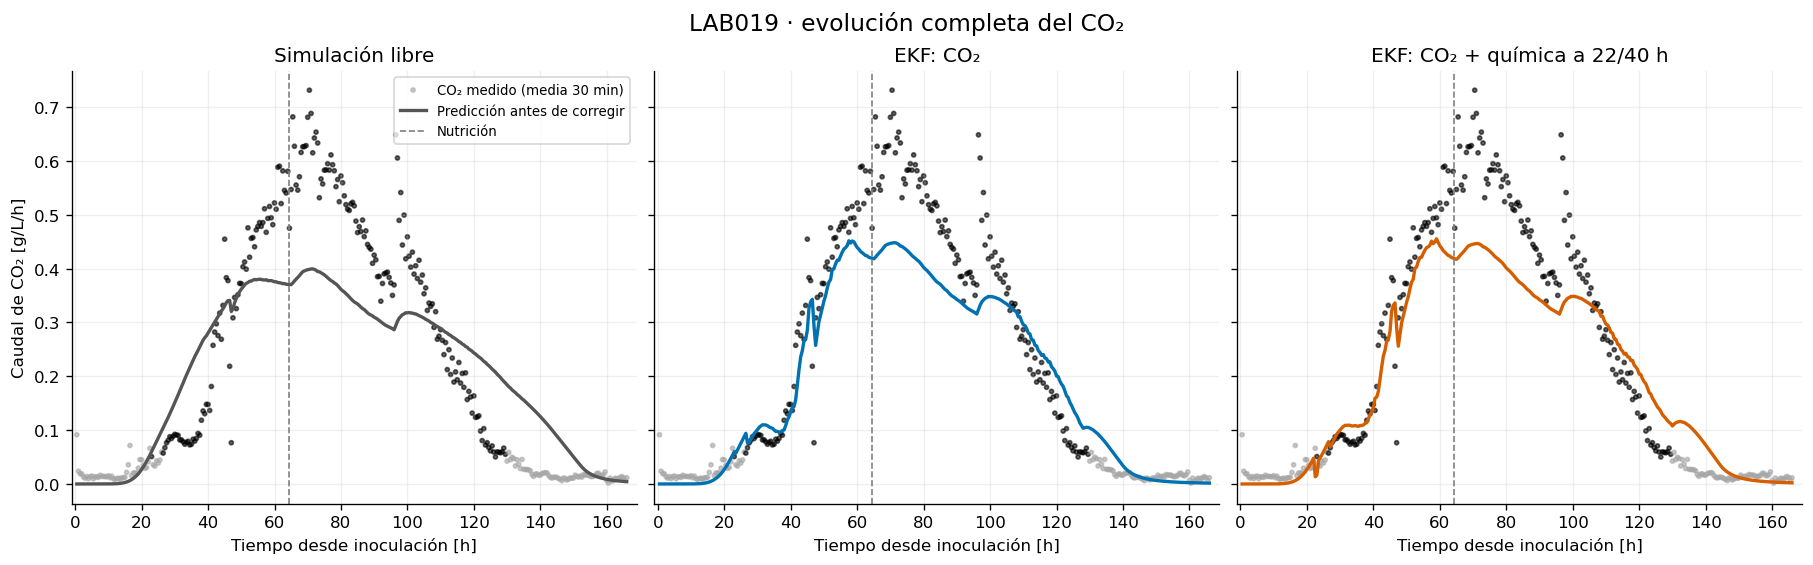

In [6]:
COLORS={'Libre':'#555555','CO₂':'#0072B2','CO₂ + química':'#D55E00'}
TITLES={'Libre':'Simulación libre','CO₂':'EKF: CO₂','CO₂ + química':'EKF: CO₂ + química a 22/40 h'}
fig,axes=plt.subplots(1,3,figsize=(15,4.6),sharex=True,sharey=True,constrained_layout=True)
for ax,(name,r) in zip(axes,RUNS.items()):
    valid=gas_obs[gas_obs.valid]
    ax.scatter(valid.t_h,valid.q,s=6,c=np.where(valid.assimilate,'black','.65'),alpha=.6,label='CO₂ medido (media 30 min)')
    ax.plot(r['forecast'].t_h,r['forecast'].predicted,color=COLORS[name],lw=2,label='Predicción antes de corregir')
    ax.axvline(TP,color='.5',ls='--',lw=1,label='Nutrición')
    ax.set(title=TITLES[name],xlabel='Tiempo desde inoculación [h]',xlim=(-1,HORIZON+3))
axes[0].set_ylabel('Caudal de CO₂ [g/L/h]')
axes[0].legend(fontsize=8,loc='upper right')
fig.suptitle('LAB019 · evolución completa del CO₂',fontsize=14)
plt.show()

In [7]:
reserved=chem.loc[chem.role.eq('reservada')].copy()
evaluation=[]
for name,r in RUNS.items():
    for _,sample in reserved.iterrows():
        for channel,column in CHANNELS.items():
            if pd.notna(sample[column]):
                censored=channel=='GF' and str(sample.GF_zero_substitution).lower()=='true'
                prediction=np.interp(sample.t_h,r['frame'].index,r['frame'][channel])
                evaluation.append(dict(scenario=name,t_h=sample.t_h,channel=channel,
                    observed=sample[column],predicted=prediction,error=prediction-sample[column],censored=censored))
evaluation=pd.DataFrame(evaluation)
metrics=evaluation[~evaluation.censored].groupby(['scenario','channel']).agg(
    n=('error','size'),RMSE=('error',lambda e:np.sqrt(np.mean(e**2))),MAE=('error',lambda e:np.mean(abs(e)))).reset_index()
LABELS={'GF':('Azúcar total', 'g/L',1.),'N':('Nitrógeno asimilable','mg/L',1000.),
        'E':('Etanol','g/L',1.),'X':('Biomasa viable','g/L',1.)}

def complete_curve(channel):
    label,unit,factor=LABELS[channel]
    fig,axes=plt.subplots(1,3,figsize=(15,4.6),sharex=True,sharey=True,constrained_layout=True)
    values=[]
    for name,r in RUNS.items():values.extend((r['frame'][channel]*factor).to_numpy())
    valid=reserved.dropna(subset=[CHANNELS[channel]])
    values.extend(valid[CHANNELS[channel]].to_numpy()*factor)
    lo,hi=np.nanmin(values),np.nanmax(values);pad=max((hi-lo)*.12,.01)
    for ax,(name,r) in zip(axes,RUNS.items()):
        ax.plot(r['frame'].index,r['frame'][channel]*factor,color=COLORS[name],lw=2,
                label='Simulación' if name=='Libre' else 'Estimación EKF')
        uncensored=np.ones(len(valid),bool)
        if channel=='GF':uncensored=~valid.GF_zero_substitution.astype(str).str.lower().eq('true').to_numpy()
        ax.scatter(valid.t_h.to_numpy()[uncensored],valid[CHANNELS[channel]].to_numpy()[uncensored]*factor,
                   c='black',s=30,zorder=5,label='Muestras reservadas')
        if (~uncensored).any():
            ax.scatter(valid.t_h.to_numpy()[~uncensored],valid[CHANNELS[channel]].to_numpy()[~uncensored]*factor,
                       facecolors='white',edgecolors='black',marker='v',s=45,zorder=5,label='Resultado final censurado')
        if name=='CO₂ + química' and channel in ['GF','N']:
            selected=chem[chem.t_h.isin(CHEM_TIMES)]
            ax.scatter(selected.t_h,selected[CHANNELS[channel]]*factor,c='#CC0000',marker='*',s=120,
                       edgecolors='white',linewidths=.4,zorder=6,label='Mediciones usadas para corregir')
        ax.axvline(TP,color='.5',ls='--',lw=1,label='Nutrición')
        ax.set(title=TITLES[name],xlabel='Tiempo desde inoculación [h]',xlim=(-1,HORIZON+3),ylim=(lo-pad,hi+pad))
    axes[0].set_ylabel(f'{label} [{unit}]')
    # Put legends inside their own panels; no shared legend can confuse assimilated channels.
    for ax in axes:ax.legend(fontsize=7,loc='best')
    fig.suptitle(f'LAB019 · curva completa de {label.lower()}',fontsize=14)
    plt.show()
    m=metrics[metrics.channel.eq(channel)].set_index('scenario')
    display(Markdown('**Error frente a muestras reservadas:** '+ '; '.join(
        f"{TITLES[name]}: RMSE {m.loc[name,'RMSE']*factor:.3g} {unit} (n={int(m.loc[name,'n'])})" for name in RUNS)+'.'))

## Curva completa de azúcar total

**Pregunta:** ¿Se reproduce el consumo de azúcar hasta el final? La medición final proviene de un resultado negativo sustituido por cero: se marca como censurada y no entra en el RMSE.

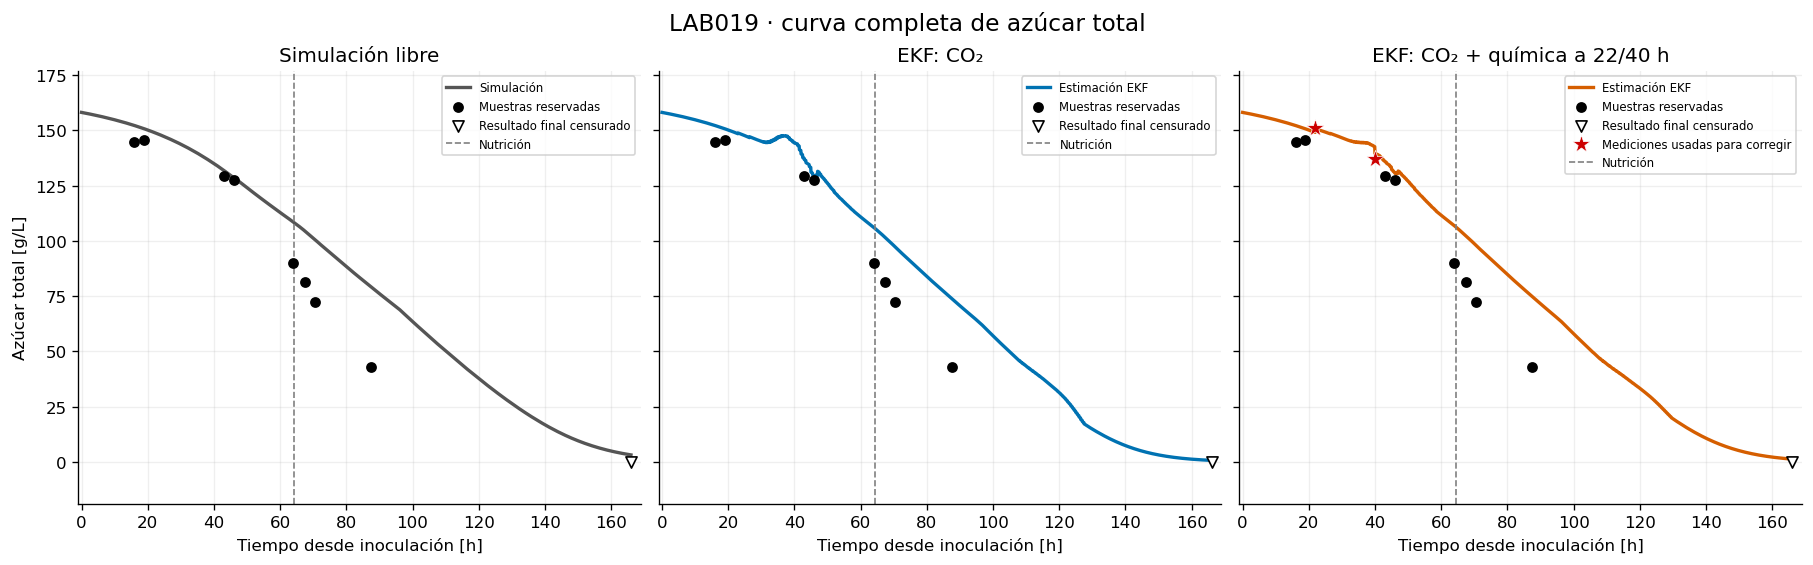

**Error frente a muestras reservadas:** Simulación libre: RMSE 19.6 g/L (n=8); EKF: CO₂: RMSE 17.2 g/L (n=8); EKF: CO₂ + química a 22/40 h: RMSE 17.7 g/L (n=8).

In [8]:
complete_curve('GF')

## Curva completa de nitrógeno

**Pregunta:** ¿Se reproduce el agotamiento y la respuesta al aporte de nitrógeno? Las estrellas rojas son las únicas dos mediciones químicas usadas por el filtro. La nutrición es una entrada conocida, no una medición.

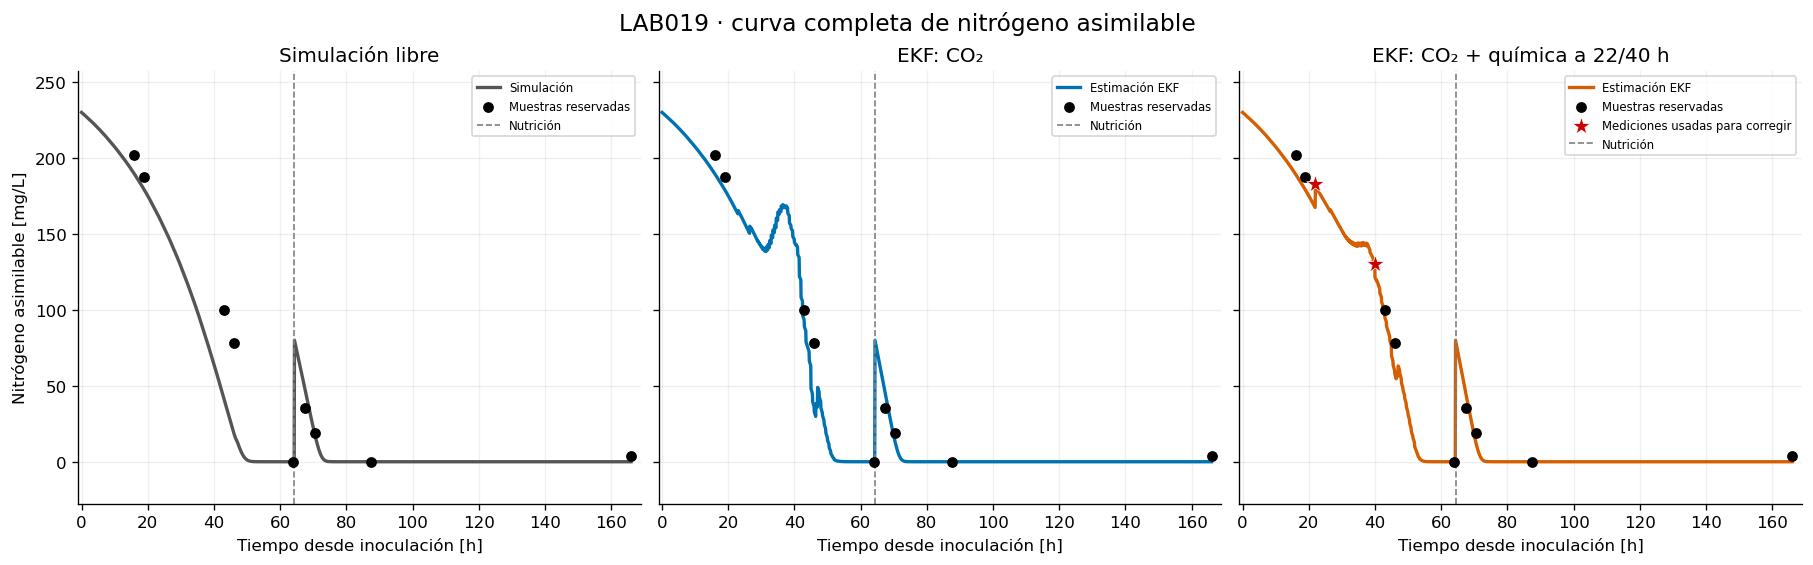

**Error frente a muestras reservadas:** Simulación libre: RMSE 28.5 mg/L (n=9); EKF: CO₂: RMSE 16.8 mg/L (n=9); EKF: CO₂ + química a 22/40 h: RMSE 9.47 mg/L (n=9).

In [9]:
complete_curve('N')

## Curva completa de etanol

**Pregunta:** ¿El etanol predicho concuerda con las muestras que el filtro nunca ha recibido? Aquí todas las mediciones dibujadas son reservadas; no se asimila etanol.

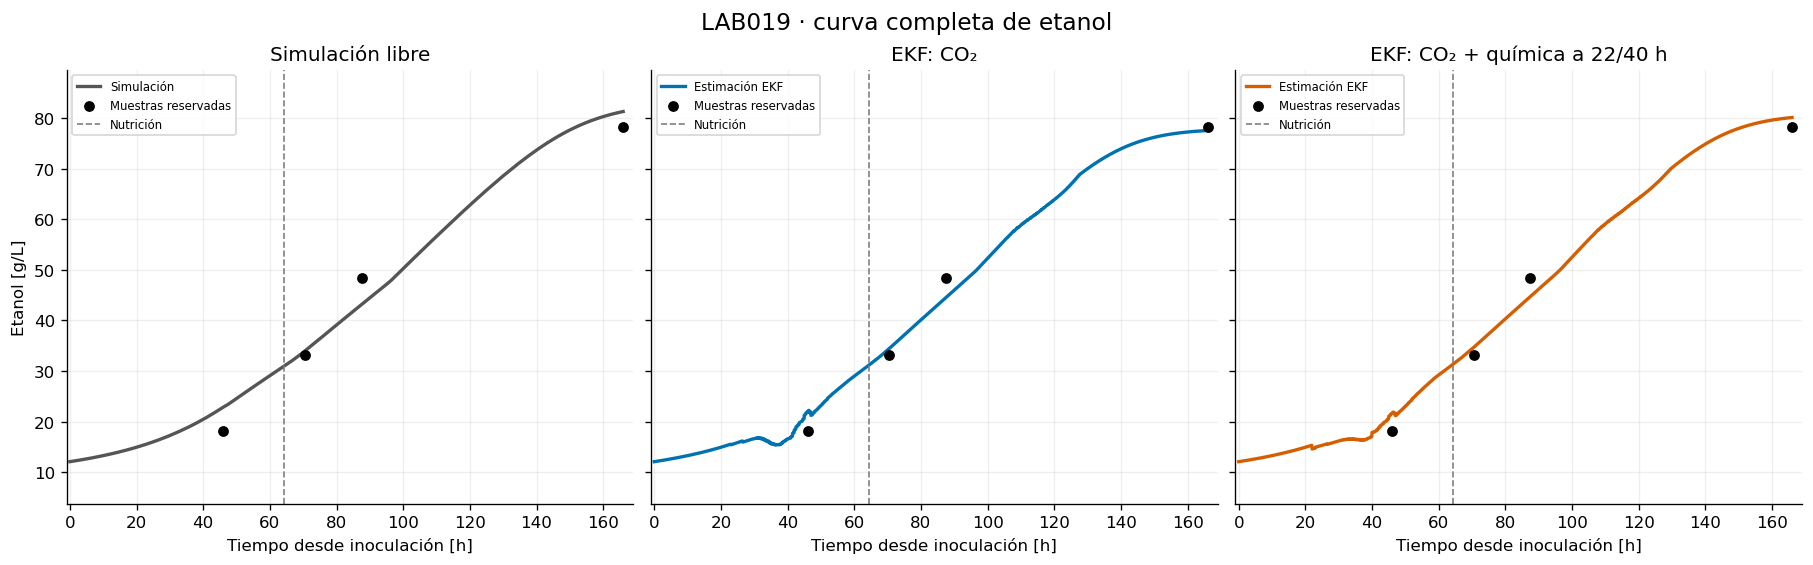

**Error frente a muestras reservadas:** Simulación libre: RMSE 3.85 g/L (n=4); EKF: CO₂: RMSE 2.82 g/L (n=4); EKF: CO₂ + química a 22/40 h: RMSE 2.82 g/L (n=4).

In [10]:
complete_curve('E')

## Curva completa de biomasa viable

**Pregunta:** ¿La biomasa viable estimada sigue el contraste disponible? Oculyze se muestra como referencia con incertidumbre metrológica pendiente; no se usa para ajustar el filtro ni como verdad exacta.

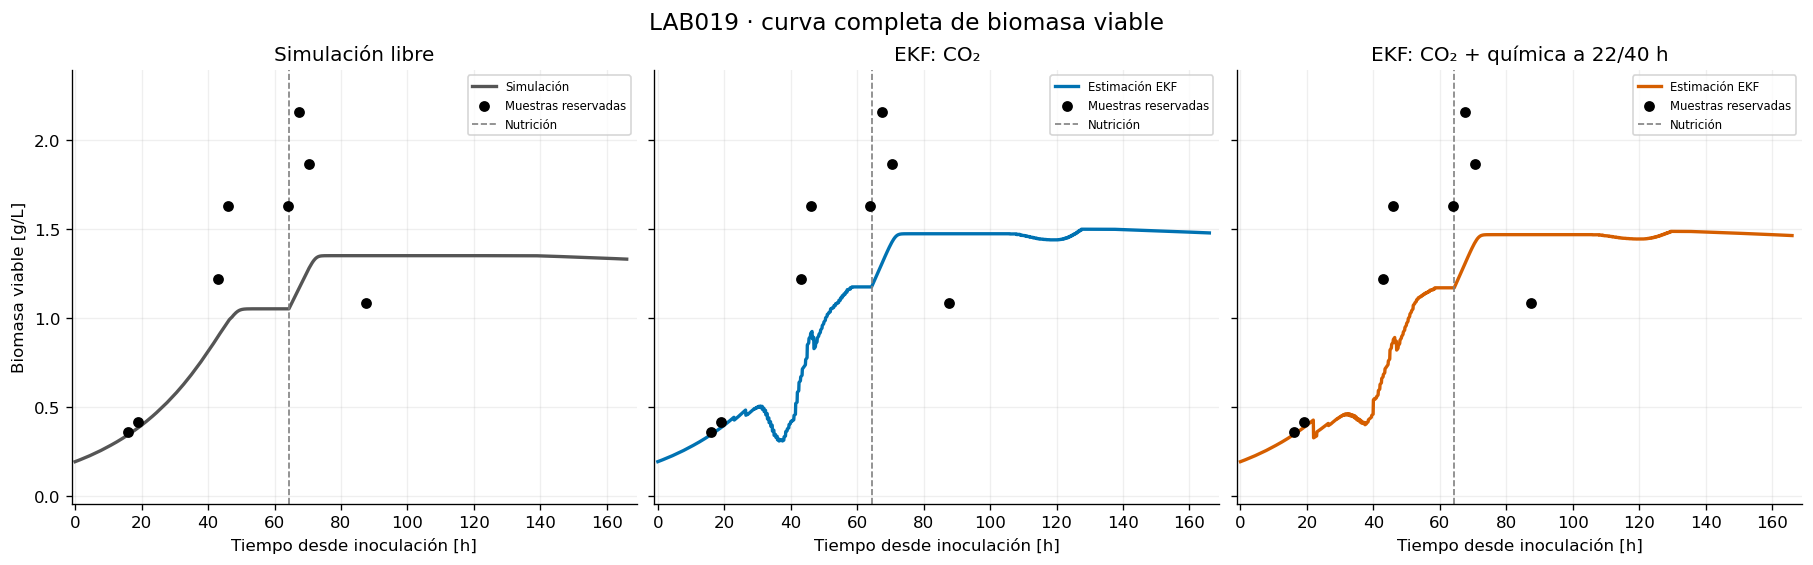

**Error frente a muestras reservadas:** Simulación libre: RMSE 0.53 g/L (n=8); EKF: CO₂: RMSE 0.511 g/L (n=8); EKF: CO₂ + química a 22/40 h: RMSE 0.517 g/L (n=8).

In [11]:
complete_curve('X')

## Qué mejora y qué empeora

La tabla usa sólo muestras reservadas, excluyendo iniciales, muestras de 22/40 h y el azúcar
final censurado. Se separa el tramo inicial del posterior a nutrición para no ocultar el
comportamiento tardío en una única cifra. Un menor error de gas no demuestra mejores estados.

In [12]:
summary=[]
for name,r in RUNS.items():
    d=r['diag']
    err=(r['forecast'].predicted-r['forecast'].observed)[gas_obs.valid.to_numpy()]
    summary.append(dict(escenario=name,RMSE_CO2=float(np.sqrt(np.mean(err**2))),
        correcciones_CO2=0 if d.empty else int(d.channel.eq('CO2').sum()),
        correcciones_quimicas=0 if d.empty else int(d.channel.eq('GF+N').sum()),
        amortiguadas=0 if d.empty else int(d.alpha.lt(.999999).sum()),
        predicciones_negativas=len(r['negative'])))
display(pd.DataFrame(summary))
for row in summary:
    if row['correcciones_CO2']:
        display(Markdown(f"**{TITLES[row['escenario']]}:** {row['amortiguadas']} actualizaciones amortiguadas. "
            'Una frecuencia elevada indica que la actualización gaussiana intenta salir del dominio no negativo; '
            'este prototipo no puede considerarse validado por reducir el RMSE.'))
sections=[]
for label,mask in [('Antes de nutrición',evaluation.t_h<TP),('Después de nutrición',evaluation.t_h>TP)]:
    part=evaluation[mask&~evaluation.censored]
    for (name,ch),d in part.groupby(['scenario','channel']):
        label_ch,unit,factor=LABELS[ch]
        sections.append(dict(tramo=label,variable=label_ch,unidad=unit,escenario=name,n=len(d),
                             RMSE=float(np.sqrt(np.mean(d.error**2)))*factor))
display(pd.DataFrame(sections))
display(Markdown('Los resultados deben interpretarse por variable y por tramo. Las correcciones de 22/40 h '
    'no añaden información química posterior a nutrición. Las discrepancias tardías pueden reflejar la capa '
    'postnutrición heredada, inicialización, incertidumbre omitida o limitaciones del EKF.'))

,escenario,RMSE_CO2,correcciones_CO2,correcciones_quimicas,amortiguadas,predicciones_negativas
0,Libre,0.115674,0,0,0,0
1,CO₂,0.080689,208,0,102,0
2,CO₂ + química,0.082751,208,2,98,0


**EKF: CO₂:** 102 actualizaciones amortiguadas. Una frecuencia elevada indica que la actualización gaussiana intenta salir del dominio no negativo; este prototipo no puede considerarse validado por reducir el RMSE.

**EKF: CO₂ + química a 22/40 h:** 98 actualizaciones amortiguadas. Una frecuencia elevada indica que la actualización gaussiana intenta salir del dominio no negativo; este prototipo no puede considerarse validado por reducir el RMSE.

,tramo,variable,unidad,escenario,n,RMSE
0,Antes de nutrición,Etanol,g/L,CO₂,1,3.828668
1,Antes de nutrición,Azúcar total,g/L,CO₂,5,8.892393
2,Antes de nutrición,Nitrógeno asimilable,mg/L,CO₂,5,21.944759
3,Antes de nutrición,Biomasa viable,g/L,CO₂,5,0.451932
4,Antes de nutrición,Etanol,g/L,CO₂ + química,1,3.497626
5,Antes de nutrición,Azúcar total,g/L,CO₂ + química,5,9.132814
6,Antes de nutrición,Nitrógeno asimilable,mg/L,CO₂ + química,5,11.557342
7,Antes de nutrición,Biomasa viable,g/L,CO₂ + química,5,0.460732
8,Antes de nutrición,Etanol,g/L,Libre,1,4.635840
9,Antes de nutrición,Azúcar total,g/L,Libre,5,9.332996


Los resultados deben interpretarse por variable y por tramo. Las correcciones de 22/40 h no añaden información química posterior a nutrición. Las discrepancias tardías pueden reflejar la capa postnutrición heredada, inicialización, incertidumbre omitida o limitaciones del EKF.

## Anexo técnico: matrices, memoria y limitaciones

Estado físico: [X,N,G,F,E,Cd,O₂]. Memoria auxiliar: [X_ref,N_ref,G_ref,F_ref,E_ref],
trayectoria contrafactual sin aporte de N. La fuente gaseosa postnutrición utiliza ambas
trayectorias según la formulación v3 existente; se conserva su kernel causal de normalización
analítica y la rampa de actividad. No hay biomasa muerta ni glicerol en la integración.
La muerte celular conserva su efecto de pérdida en X cuando la cinética lo activa; no se
integra un inventario de biomasa muerta.

P₀ comparte exactamente las incertidumbres iniciales entre las cinco variables biológicas
y su referencia. Q comparte los canales de crecimiento/fermentación entre ambas trayectorias;
la perturbación de Cd es independiente. Se conservan las mismas intensidades exploratorias
del primer ensayo. El pulso de 0,08 g/L se aplica una única vez al N físico y no a N_ref;
su incertidumbre no se estima en este prototipo.

La temperatura es exógena; sus errores no están incluidos en P. Puerta por consumo de azúcar
2–10 g/L, parámetros fijos de transferencia entrenados en LAB016–018, sin reajuste.
La puerta heredada afecta sólo la capa gaseosa y su balance global de carbono sigue pendiente.
Los parámetros fueron calibrados sobre procesamiento offline: su transferencia causal no es
una validación independiente de la arquitectura.

R_CO₂=(0,04 g/L/h)²; R_química=diag[(2 g/L)²,(0,015 g/L)²], orden [GF,N]. Son escalas
de trabajo y no precisiones instrumentales verificadas. Q_d≈Q_c·Δt para pasos de cinco minutos.
Se conserva un acumulador de gas por ventana de 30 min, con covarianza cruzada con el estado.
La actualización es Joseph; las ganancias que intentan cruzar cero se amortiguan y se cuentan.
La positividad no convierte las covarianzas en intervalos calibrados. Los bins bajo el umbral
de detección se omiten, no se interpreta cada cero como una observación gaussiana exacta.

In [13]:
display(Markdown('**P₀ físico (7×7)**'));display(pd.DataFrame(Pphysical,index=PHYSICAL,columns=PHYSICAL))
display(Markdown('**Q_c físico (7×7), y Q_d a cinco minutos**'))
display(pd.DataFrame(Qc[:7,:7],index=PHYSICAL,columns=PHYSICAL))
display(pd.DataFrame(Qc[:7,:7]/12,index=PHYSICAL,columns=PHYSICAL))
display(Markdown('**P₀ completo, incluida la memoria (12×12)**'))
display(pd.DataFrame(P0,index=STATE,columns=STATE))
display(Markdown('**Q_c completo, incluida la memoria (12×12)**'))
display(pd.DataFrame(Qc,index=STATE,columns=STATE))
display(pd.DataFrame(Rchem,index=['GF','N'],columns=['GF','N']))
display(pd.DataFrame(Hchem/SCALE[None,:],index=['GF','N'],columns=STATE))
z=RUNS['CO₂']['frame'].loc[24.,STATE].to_numpy(float)/SCALE
p,q,F,H=linearized(z,24,24+1/12)
display(Markdown('**F físico completo: ejemplo 24 → 24,0833 h**'))
display(pd.DataFrame(F*SCALE[:,None]/SCALE[None,:],index=STATE,columns=STATE))
display(Markdown('**H_CO₂ al completar la ventana respecto a [z,A]:**'))
display(pd.DataFrame([[0.]*NS+[1/BIN_H]],columns=STATE+['A']))
display(choice[['training','stage','kCO2_release_h','CO2sat_scale','matrix_gain']])
display(theta_table[~theta_table.parameter.str.startswith('gamma')][['parameter','theta']])

**P₀ físico (7×7)**

,X,N,G,F,E,Cd,O2
X,0.036437,0.000000,0.0,0.0,0.00,0.0000,0.00000
N,0.000000,0.000225,0.0,0.0,0.00,0.0000,0.00000
G,0.000000,0.000000,1.0,-1.0,0.00,0.0000,0.00000
F,0.000000,0.000000,-1.0,5.0,0.00,0.0000,0.00000
E,0.000000,0.000000,0.0,0.0,0.25,0.0000,0.00000
Cd,0.000000,0.000000,0.0,0.0,0.00,0.0025,0.00000
O2,0.000000,0.000000,0.0,0.0,0.00,0.0000,0.56079


**Q_c físico (7×7), y Q_d a cinco minutos**

,X,N,G,F,E,Cd,O2
X,0.000009,-2.409862e-06,-0.000009,-0.000008,0.000000,0.000000,0.0
N,-0.000002,6.452707e-07,0.000002,0.000002,0.000000,0.000000,0.0
G,-0.000009,2.494440e-06,0.006410,0.000008,-0.001603,-0.001531,0.0
F,-0.000008,2.171251e-06,0.000008,0.006407,-0.004384,-0.004188,0.0
E,0.000000,0.000000e+00,-0.001603,-0.004384,0.003404,0.003251,0.0
Cd,0.000000,0.000000e+00,-0.001531,-0.004188,0.003251,0.003206,0.0
O2,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.0


,X,N,G,F,E,Cd,O2
X,7.500000e-07,-2.008219e-07,-7.763223e-07,-6.757391e-07,0.000000,0.000000,0.0
N,-2.008219e-07,5.377256e-08,2.078700e-07,1.809376e-07,0.000000,0.000000,0.0
G,-7.763223e-07,2.078700e-07,5.341369e-04,6.994551e-07,-0.000134,-0.000128,0.0
F,-6.757391e-07,1.809376e-07,6.994551e-07,5.339422e-04,-0.000365,-0.000349,0.0
E,0.000000e+00,0.000000e+00,-1.335439e-04,-3.652943e-04,0.000284,0.000271,0.0
Cd,0.000000e+00,0.000000e+00,-1.275726e-04,-3.489604e-04,0.000271,0.000267,0.0
O2,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.0


...

,X,N,G,F,E,Cd,O2,X_ref,N_ref,G_ref,F_ref,E_ref
X,1.003065,3.958690e-04,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
N,-0.000821,9.998940e-01,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
G,-0.077450,-4.246772e-04,0.999975,0.000002,0.000861,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
F,-0.036749,-3.634835e-04,0.000168,0.999962,0.000389,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
E,0.041232,8.266055e-06,-0.000108,0.000024,0.999518,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Cd,0.000004,2.371436e-08,-0.000068,-0.000068,0.000005,0.97608,-0.011831,0.023517,0.000005,-0.000062,0.000014,-0.000274
O2,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.00000,0.998312,-0.009047,-0.000002,0.000000,0.000000,0.000000
X_ref,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.00000,0.000000,1.003065,0.000396,0.000000,0.000000,0.000000
N_ref,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.00000,0.000000,-0.000821,0.999894,0.000000,0.000000,0.000000
G_ref,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.00000,0.000000,-0.077450,-0.000425,0.999975,0.000002,0.000861


**H_CO₂ al completar la ventana respecto a [z,A]:**

,X,N,G,F,E,Cd,O2,X_ref,N_ref,G_ref,F_ref,E_ref,A
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0


,training,stage,kCO2_release_h,CO2sat_scale,matrix_gain
4,train_016_018,Z1,0.424588,0.35139,0.880749


,parameter,theta
0,mu0,0.078728
1,sN,8.751446
2,qN,0.021080
3,qXG,0.081491
4,qXF,0.070933
5,betaG0,0.428878
6,sG,0.097455
7,betaF0,3.440399
8,sF,0.178295
9,qEG,1.712807


## Comprobaciones y trazabilidad

Se verifica el RHS reducido contra las cinco ecuaciones oficiales, la convergencia del paso,
los Jacobianos, el balance del reservorio en cada transición, el pulso único y la invariancia
del filtro frente a cambios de las muestras reservadas. SOURCE no contiene outputs;
EXECUTED contiene las curvas y tablas. El notebook no escribe datos o parámetros históricos.

In [14]:
refined,qr=transition_batch(z,24,24+1/12,internal_h=1/120)
refinement=max(np.max(abs((p-refined[0])*SCALE)),abs(q-qr[0]))
_,_,Fhalf,_=linearized(z,24,24+1/12,eps=5e-6)
fd_error=np.linalg.norm(F-Fhalf)/max(np.linalg.norm(F),1e-12)
assert refinement<1e-4 and fd_error<1e-3,(refinement,fd_error)
saved=chem.copy()
chem.loc[chem.role.eq('reservada'),list(CHANNELS.values())]=999.
control=run_scenario('control',True,True)
chem=saved
invariance=float(np.max(abs(control['frame'][STATE].to_numpy()-RUNS['CO₂ + química']['frame'][STATE].to_numpy())))
assert invariance==0
prefix=RUNS['CO₂']['frame'].index<22.
assert np.array_equal(RUNS['CO₂']['frame'].loc[prefix,STATE],RUNS['CO₂ + química']['frame'].loc[prefix,STATE])
assert all(r['pulse_count']==1 for r in RUNS.values())
for r in RUNS.values():
    f=r['frame'];before=f.index<TP-1e-8
    memory_error=np.max(abs(f.loc[before,PHYSICAL[:5]].to_numpy()-f.loc[before,STATE[7:12]].to_numpy()))
    assert memory_error<1e-6,memory_error
    assert not r['negative'], 'Predicciones negativas: no interpretar como trayectoria física válida'
assert not {'Xd','Gly'}&set(STATE)
assert {str(path.relative_to(ROOT)):sha(path) for path in INPUTS}==HASHES
checks=dict(reduced_rhs_error=float(max(core_errors)),refinement=float(refinement),FD=float(fd_error),
            reserved_invariance=invariance,unique_nutrition=True,physical_states=PHYSICAL,
            final_horizon=HORIZON,input_hashes_verified=True)
display(checks)
TRACE=dict(created_at=datetime.now(ZoneInfo('America/Santiago')).isoformat(),
    executable=sys.executable,state_order=STATE,initial=x0.tolist(),inputs=HASHES,
    theta={k:v for k,v in theta.items() if not k.startswith('gamma')},gas=gas_params,
    P0=P0.tolist(),Qc=Qc.tolist(),Rgas=Rgas,Rchem=Rchem.tolist(),checks=checks)
display(pd.DataFrame(HASHES.items(),columns=['entrada','SHA256']))
print('Verificado: datos intactos, pulso único, química reservada no utilizada, sin commit/push.')

{'reduced_rhs_error': 5.551115123125783e-17,
 'refinement': 1.5396017793989358e-13,
 'FD': 3.1647986765352378e-09,
 'reserved_invariance': 0.0,
 'unique_nutrition': True,
 'physical_states': ['X', 'N', 'G', 'F', 'E', 'Cd', 'O2'],
 'final_horizon': 166.0,
 'input_hashes_verified': True}

,entrada,SHA256
0,fermentation_model\data\mem2026\LAB019-021\bac...,5ff5731b4724e71d5f2a663b19fc3b2cd78fa27a88b6c1...
1,fermentation_model\data\mem2026\LAB019-021\bac...,b5a2565615adbabe4021ad2d5559b50fa06e30773499b0...
2,fermentation_model\laboratory_2026\results\co2...,caf299f8fe5ff92b42808cf791a0cce5600f220729ed76...
3,fermentation_model\laboratory_2026\results\co2...,a9392dfe49357a2f35e155b6aac0d612ee4472b72ace47...
4,fermentation_model\laboratory_2026\results\co2...,f9c5efdc19c67bbb16d8eec30f76060f07f090b23422d6...
5,fermentation_model\laboratory_2026\notebooks\d...,e9da3ed11cc4f529866326fadfc682a4dbb836473d72ec...
6,fermentation_model\laboratory_2026\results\nit...,0ccfa4607c2d2e7494af14f0ec7d65b16ae63caab31a30...
7,fermentation_model\laboratory_2026\results\est...,3876c53d0b4dc6f4126ffb4f8e0999a8455c90f283c345...
8,fermentation_model\shared\run_new_must_glycero...,1571a1d5eddb4daba1a27374529daf9b4d56d6a6de0fcd...
9,.git\lfs\objects\3c\af\3caf3325257e64fc0d7024a...,3caf3325257e64fc0d7024a70ff42d69e98bd2c8764a7f...


Verificado: datos intactos, pulso único, química reservada no utilizada, sin commit/push.
